In [80]:
import sys
import math

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../..")

from notebooks.constants import Configs

In [81]:
def read_files(files):
    dfs = []

    for lf in files:
        df = pd.read_csv(lf, delimiter=';')
        dfs.append(df)

    df = pd.concat(dfs, ignore_index=True)
    df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
    df = df.ffill().bfill()

    mapa_mov = {0: 'Pick', 1: 'Place', 6: 'Park'} 
    df['movLabel'] = df['movType'].map(mapa_mov)
    
    return df

In [82]:
left_files = read_files(Configs.SMART_RETAIL_LEFT_FILES)
right_files = read_files(Configs.SMART_RETAIL_RIGHT_FILES)

In [83]:
REP_ID_TO_SHOW = 5
left_files_last_repID = left_files[left_files["repID"] == 5]
right_files_last_repID = right_files[right_files["repID"] == 5]

In [84]:
left_files_last_repID

,sub,repID,movID,movType,step,xs,ys,zs,xe,ye,ze,xw,yw,zw,vel,acc,t,k,movLabel
4086,1,5,1,0,1,22.093,-173.553,1455.73,91.834,-184.942,1142.44,70.924,-128.835,886.722,0.155454,0.317403,4.229786,12.874541,Pick
4087,1,5,1,0,2,22.836,-174.064,1455.30,91.781,-184.238,1141.80,72.311,-130.433,885.466,0.156587,0.611325,3.474124,24.405506,Pick
4088,1,5,1,0,3,23.566,-174.590,1454.85,91.570,-183.549,1141.11,72.810,-132.494,884.162,0.160220,1.125001,3.893780,42.320745,Pick
4089,1,5,1,0,4,24.345,-175.140,1454.44,91.145,-182.808,1140.40,72.514,-134.796,882.861,0.167078,1.470824,5.608095,49.617346,Pick
4090,1,5,1,0,5,25.212,-175.707,1454.10,90.554,-181.979,1139.73,71.714,-137.400,881.589,0.177170,1.659967,7.500507,48.517264,Pick
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104785,19,5,12,6,77,-46.419,-134.236,1438.80,41.071,-169.316,1154.71,-17.169,-177.989,917.255,0.071203,1.132732,79.768574,189.288878,Park
104786,19,5,12,6,78,-45.925,-133.837,1438.89,41.554,-169.092,1154.82,-15.883,-177.540,917.160,0.062902,1.126195,78.147067,265.307355,Park
104787,19,5,12,6,79,-45.266,-133.727,1438.92,42.020,-169.202,1154.82,-14.582,-177.604,916.956,0.057782,1.067749,86.567901,313.191269,Park
104788,19,5,12,6,80,-44.521,-133.970,1438.89,42.507,-169.484,1154.71,-13.495,-177.827,916.705,0.055464,0.966164,102.557158,313.298087,Park


In [85]:
MOVEMENT_TO_SHOW = "Pick"
left_files_last_repID = left_files_last_repID[left_files_last_repID["movLabel"] == MOVEMENT_TO_SHOW]
right_files_last_repID = right_files_last_repID[right_files_last_repID["movLabel"] == MOVEMENT_TO_SHOW]

In [86]:
left_files_last_repID[left_files_last_repID["movID"] == 5].head(10)

,sub,repID,movID,movType,step,xs,ys,zs,xe,ye,ze,xw,yw,zw,vel,acc,t,k,movLabel
4485,1,5,5,0,1,-9.619,-193.153,1456.22,-279.063,-266.774,1297.73,-530.987,-331.986,1333.24,0.288682,3.396367,-7.726449,28.469951,Pick
4486,1,5,5,0,2,-8.073,-193.949,1455.38,-273.733,-270.889,1292.15,-526.083,-331.283,1332.78,0.333194,3.850690,1.740335,22.974343,Pick
4487,1,5,5,0,3,-6.338,-194.721,1454.70,-267.511,-275.665,1286.25,-520.207,-331.091,1331.55,0.385089,4.199837,7.492326,17.593618,Pick
4488,1,5,5,0,4,-4.577,-195.494,1454.06,-260.594,-280.632,1279.86,-513.609,-330.705,1329.42,0.442929,4.428153,10.036881,13.222810,Pick
4489,1,5,5,0,5,-2.854,-196.253,1453.31,-253.109,-285.593,1272.95,-506.428,-330.180,1326.06,0.504656,4.538933,10.031373,10.003540,Pick
4490,1,5,5,0,6,-1.125,-197.034,1452.54,-245.099,-290.295,1265.67,-498.689,-329.601,1321.59,0.568072,4.539615,7.970583,7.729032,Pick
4491,1,5,5,0,7,0.655,-197.775,1451.84,-236.466,-294.752,1258.17,-490.362,-328.898,1316.05,0.631024,4.430508,4.354697,6.106263,Pick
4492,1,5,5,0,8,2.482,-198.430,1451.37,-227.150,-298.896,1250.58,-481.434,-327.980,1309.52,0.691451,4.200275,0.077973,4.870094,Pick
4493,1,5,5,0,9,4.376,-199.037,1450.96,-217.297,-302.372,1242.83,-472.137,-326.249,1301.70,0.747427,3.843179,-3.863582,3.860334,Pick
4494,1,5,5,0,10,6.186,-199.593,1450.53,-207.442,-304.894,1235.09,-462.990,-323.686,1292.72,0.797319,3.384898,-6.628040,3.033428,Pick


In [87]:
MOV_ID_TO_SHOW = 5
left_files_last_repID = left_files_last_repID[left_files_last_repID["movID"] == MOV_ID_TO_SHOW]
right_files_last_repID = right_files_last_repID[right_files_last_repID["movID"] == MOV_ID_TO_SHOW]

/tmp/ipykernel_17624/646259152.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


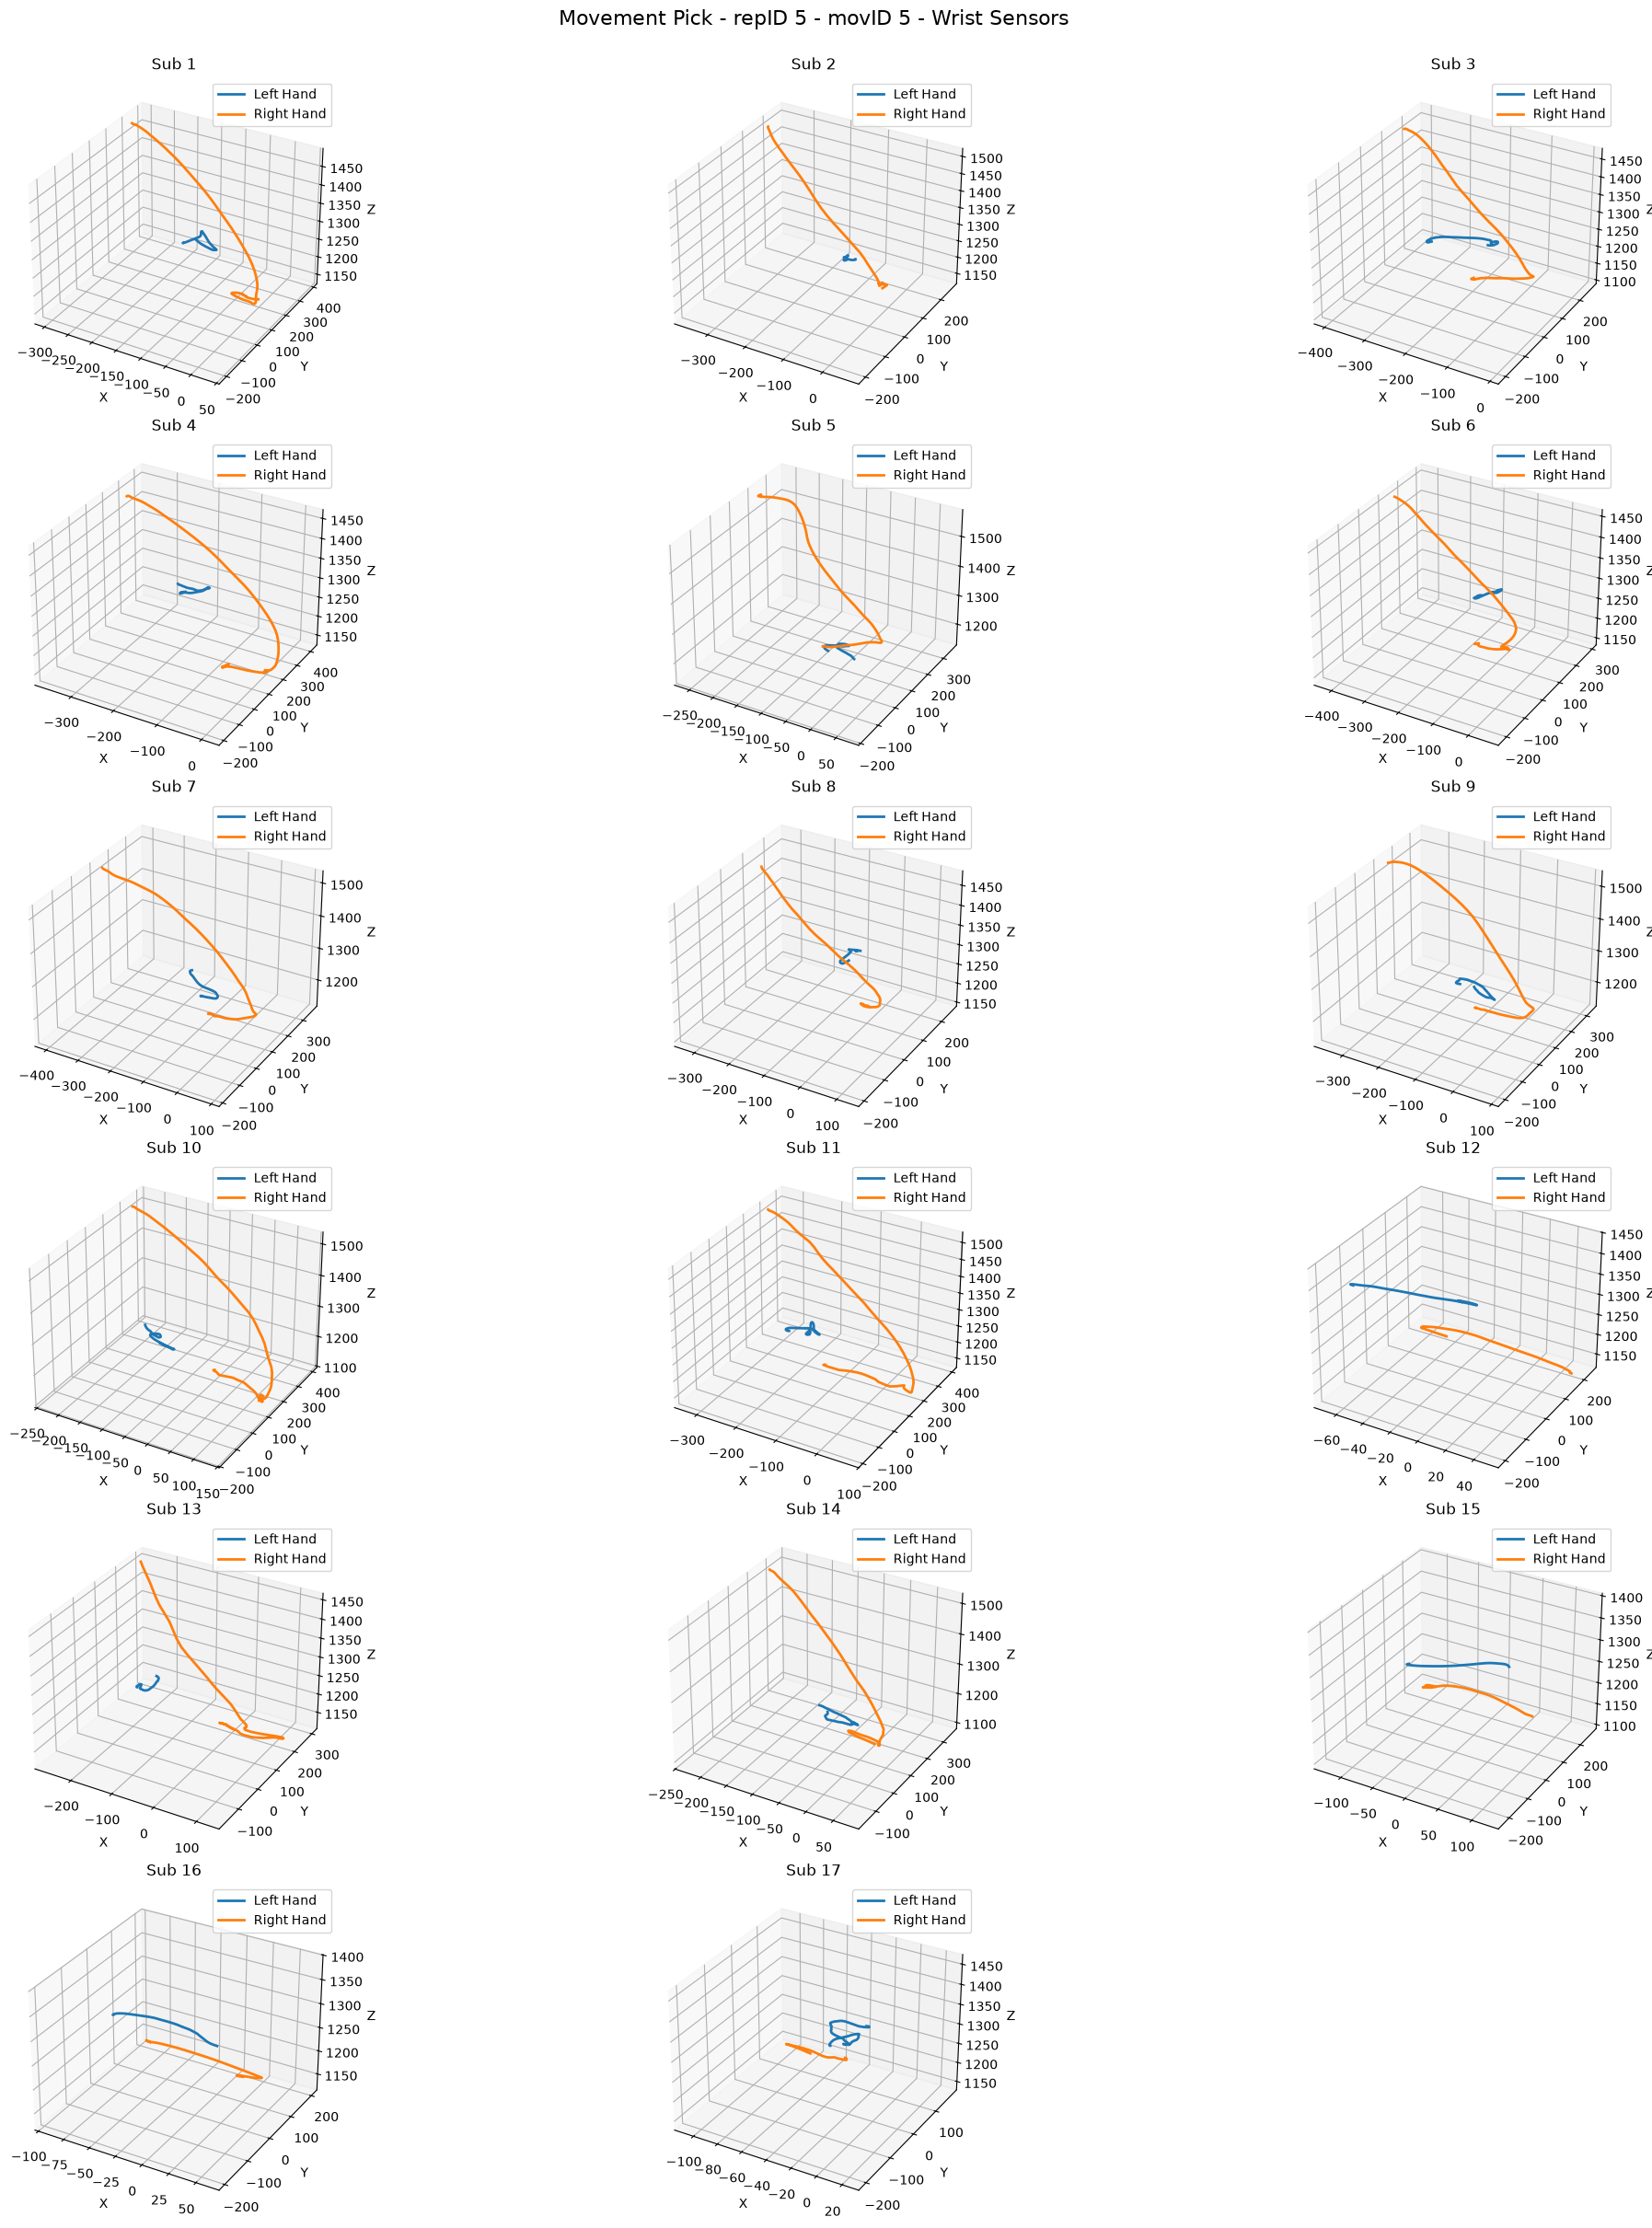

In [91]:
# Usa apenas os subjects que existem em ambas as tabelas filtradas
subs = sorted(set(left_files_last_repID["sub"]).union(right_files_last_repID["sub"]))

ncols = 3
nrows = math.ceil(len(subs) / ncols)

fig = plt.figure(figsize=(7 * ncols, 4 * nrows))

for i, sub in enumerate(subs, start=1):
    ax = fig.add_subplot(nrows, ncols, i, projection="3d")

    left_sub = left_files_last_repID[left_files_last_repID["sub"] == sub].sort_values("step")
    right_sub = right_files_last_repID[right_files_last_repID["sub"] == sub].sort_values("step")

    if not left_sub.empty:
        ax.plot(left_sub["xs"], left_sub["ys"], left_sub["zs"],
                color="tab:blue", linewidth=2, label="Left Hand")

    if not right_sub.empty:
        ax.plot(right_sub["xe"], right_sub["ye"], right_sub["ze"],
                color="tab:orange", linewidth=2, label="Right Hand")

    ax.set_title(f"Sub {sub}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.legend()

# Remove eixos vazios se a grelha sobrar com espaços
for j in range(len(subs) + 1, nrows * ncols + 1):
    fig.delaxes(fig.axes[-1])

fig.suptitle(f"Movement {MOVEMENT_TO_SHOW} - repID {REP_ID_TO_SHOW} - movID {MOV_ID_TO_SHOW} - Wrist Sensors", fontsize=16, y=1.00)
fig.tight_layout()
fig.show()